# 03 - Customer analysis: RFM and lifetime value
**Question:** who are our customers and which groups deserve different treatment?

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette=["#7C5CFF", "#22D3EE", "#FFB547", "#34E5A1", "#FF5C8A"])
pd.set_option("display.width", 140)
from python.database_loader import Database, run_named_query
db = Database(read_only=True)
from python.feature_engineering import load_delivered_orders, customer_features, portfolio_clv
from python.rfm_segmentation import rfm_segment, segment_summary
orders = load_delivered_orders(db); feat = customer_features(orders)
portfolio_clv(feat)

{'aov': 147.4166245819004,
 'orders_per_customer': 1.0440192799527839,
 'historical_clv': 153.90579824906553,
 'repeat_rate_pct': 4.0232146370253785}

In [2]:
rfm = rfm_segment(feat); summ = segment_summary(rfm); summ.round(1)

,segment,customers,revenue,avg_recency_days,avg_orders,customer_share_pct,revenue_share_pct
6,Potential Loyalists,4626,988640.8,76.5,1.0,22.8,31.6
0,At Risk,3199,890133.5,383.4,1.1,15.7,28.4
4,Need Attention,3890,586957.9,208.9,1.0,19.1,18.8
2,Hibernating,4934,340403.5,386.1,1.0,24.3,10.9
5,New Customers,3182,170039.8,75.9,1.0,15.7,5.4
1,Champions,325,99786.4,73.7,2.1,1.6,3.2
3,Loyal Customers,176,53250.7,203.6,2.1,0.9,1.7


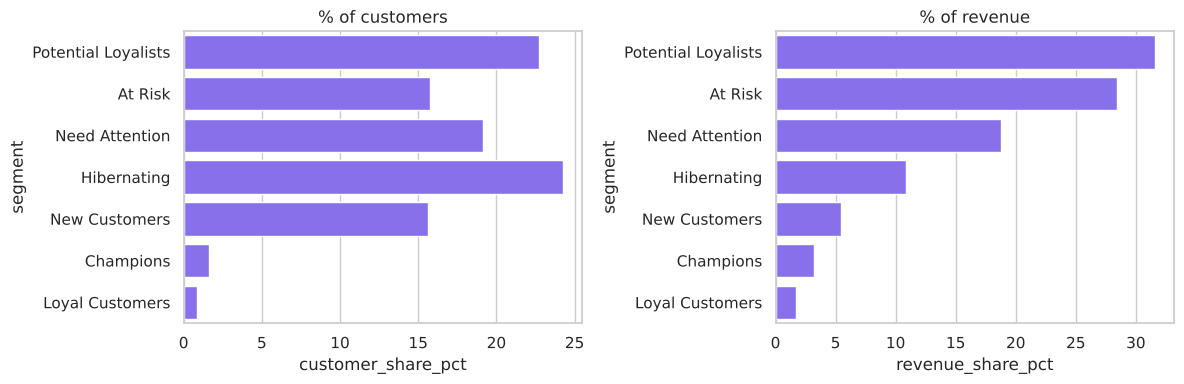

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=summ, y='segment', x='customer_share_pct', ax=ax[0]); ax[0].set_title('% of customers')
sns.barplot(data=summ, y='segment', x='revenue_share_pct', ax=ax[1]); ax[1].set_title('% of revenue'); plt.tight_layout(); plt.show()

In [4]:
run_named_query(db, 'cus_value_deciles')

,decile,customers,revenue,revenue_share_pct
0,1,2034,1133186.98,36.21
1,2,2034,495318.20,15.83
2,3,2033,359416.38,11.49
3,4,2033,285801.14,9.13
4,5,2033,231487.50,7.40
5,6,2033,191109.54,6.11
6,7,2033,155031.53,4.95
7,8,2033,123687.30,3.95
8,9,2033,93846.85,3.00
9,10,2033,60327.27,1.93


**Reading:** compare the two bars per segment. Segments whose revenue share exceeds their customer share (for example At Risk and Potential Loyalists) are the best targets for retention spend.